In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

In [19]:
# ----------- 1. Load raw dataset -----------
df_raw = pd.read_csv("../Dataset/AirQualityUCI.csv", sep=';', decimal=',')

# Remove empty columns (common in UCI dataset)
df_raw = df_raw.loc[:, ~df_raw.columns.str.fullmatch("")]

print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())

Shape: (9471, 17)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']


In [3]:
# ----------- 2. Identify missing and sentinel values -----------
sentinel = -200
missing_summary = pd.DataFrame({
    "null_count": df_raw.isna().sum(),
    "count_sentinel_-200": [
        pd.to_numeric(df_raw[c], errors="coerce").eq(sentinel).sum()
        for c in df_raw.columns
    ]
})
print("\nMissing and Sentinel Value Summary:")
print(missing_summary)


Missing and Sentinel Value Summary:
               null_count  count_sentinel_-200
Date                  114                    0
Time                  114                    0
CO(GT)                114                 1683
PT08.S1(CO)           114                  366
NMHC(GT)              114                 8443
C6H6(GT)              114                  366
PT08.S2(NMHC)         114                  366
NOx(GT)               114                 1639
PT08.S3(NOx)          114                  366
NO2(GT)               114                 1642
PT08.S4(NO2)          114                  366
PT08.S5(O3)           114                  366
T                     114                  366
RH                    114                  366
AH                    114                  366
Unnamed: 15          9471                    0
Unnamed: 16          9471                    0


In [4]:
# ----------- 3. Parse timestamps (for time and seasonal patterns) -----------
def parse_timestamp(date_str, time_str):
    t = str(time_str).replace(".", ":")
    for fmt in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return datetime.strptime(f"{date_str} {t}", fmt)
        except:
            pass
    return pd.NaT

df_raw["timestamp"] = [
    parse_timestamp(d, t) for d, t in zip(df_raw["Date"], df_raw["Time"])
]
df_raw = df_raw.dropna(subset=["timestamp"]).sort_values("timestamp")

In [5]:
# Extract time features
df_raw["hour"] = df_raw["timestamp"].dt.hour
df_raw["month"] = df_raw["timestamp"].dt.month
df_raw["year"] = df_raw["timestamp"].dt.year

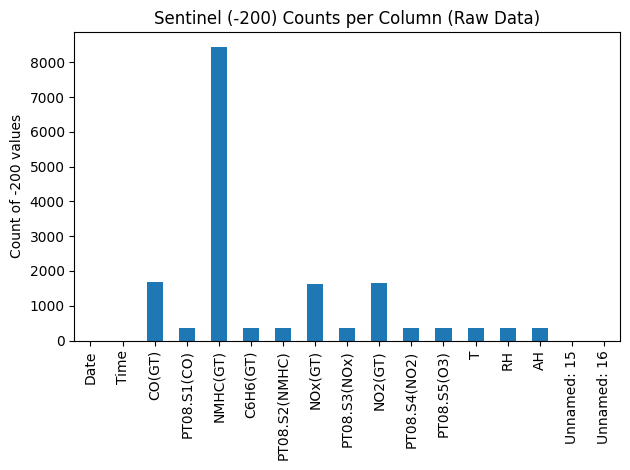

In [6]:
# ----------- 5. Visualize missingness (-200 counts) -----------
plt.figure()
missing_summary["count_sentinel_-200"].plot(kind="bar", title="Sentinel (-200) Counts per Column (Raw Data)")
plt.ylabel("Count of -200 values")
plt.tight_layout()
plt.show()

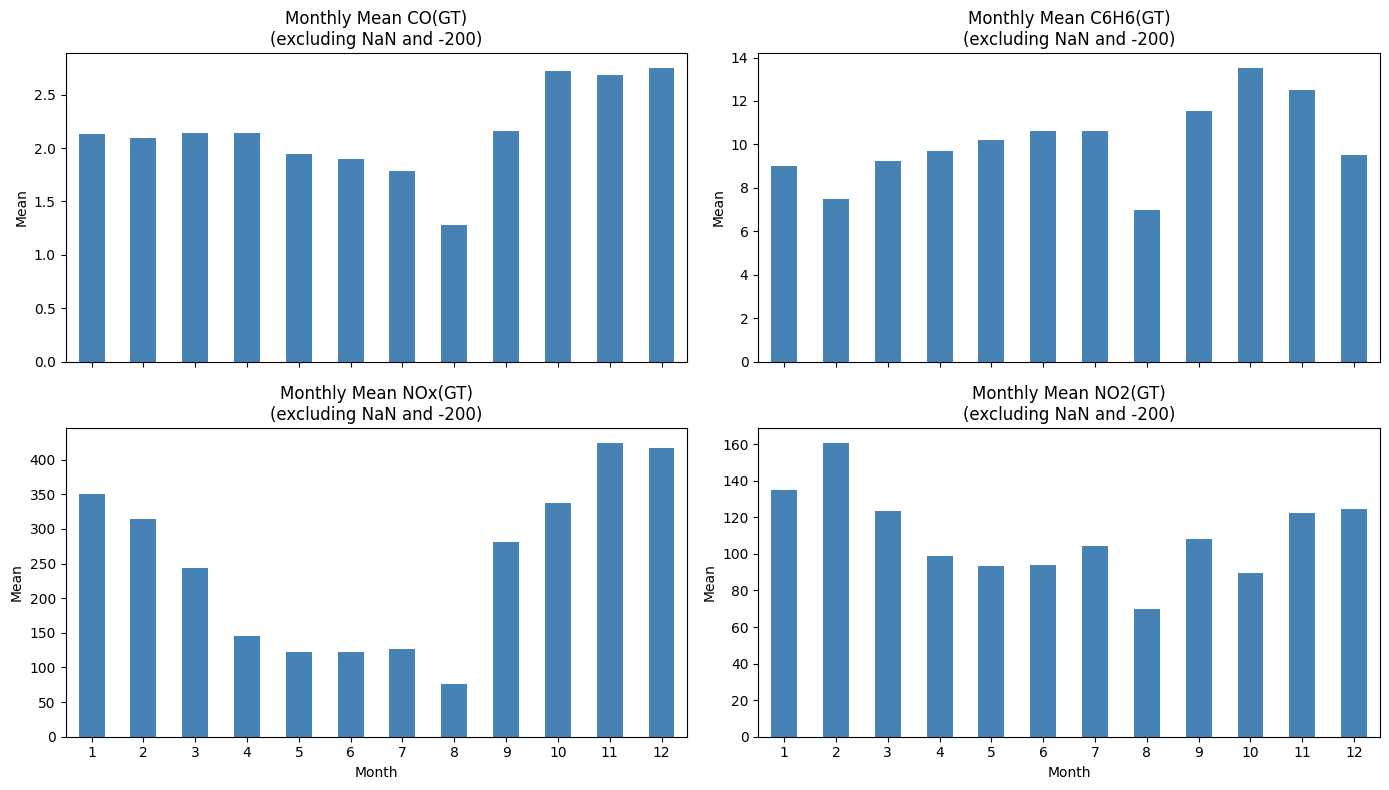

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pollutants = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]

# Convert to numeric
for col in df_raw.columns:
    if col not in ["Date", "Time", "timestamp"]:
        df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

# Time columns
df_raw["timestamp"] = pd.to_datetime(df_raw["timestamp"], errors="coerce")
if "month" not in df_raw.columns:
    df_raw["month"] = df_raw["timestamp"].dt.month

# Replace -200 with NaN (both excluded from mean)
for p in pollutants:
    if p in df_raw.columns:
        df_raw[p] = df_raw[p].replace(-200, np.nan)

# Combined monthly bar charts
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
axes = axes.flatten()

for i, p in enumerate(pollutants):
    ax = axes[i]
    if p in df_raw.columns:
        monthly = df_raw.groupby("month")[p].mean().reindex(range(1, 13))
        monthly.plot(kind="bar", ax=ax, color="steelblue")
        ax.set_title(f"Monthly Mean {p}\n(excluding NaN and -200)")
        ax.set_xlabel("Month")
        ax.set_ylabel("Mean")
        ax.tick_params(axis="x", rotation=0)
    else:
        ax.set_visible(False)

plt.tight_layout()
plt.show()


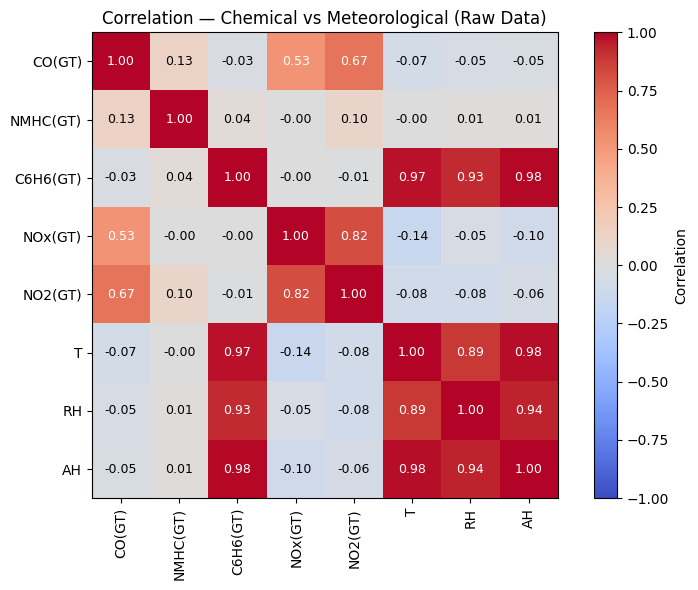

In [8]:
# ----------- 7A) Correlation: GT pollutants + meteorology (annotated) ----------
chem_cols = ["CO(GT)", "NMHC(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
met_cols  = ["T", "RH", "AH"]
corr_cols = [c for c in chem_cols + met_cols if c in df_raw.columns]

# Compute correlation on numeric copies (df_raw already coerced above)
corr = df_raw[corr_cols].corr()

plt.figure(figsize=(8, 6))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

# Numeric annotations
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr.iloc[i, j]
        plt.text(j, i, f"{val:.2f}",
                 ha="center", va="center",
                 color=("black" if abs(val) < 0.5 else "white"),
                 fontsize=9)

plt.xticks(np.arange(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(np.arange(len(corr_cols)), corr_cols)
plt.title("Correlation — Chemical vs Meteorological (Raw Data)")
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()

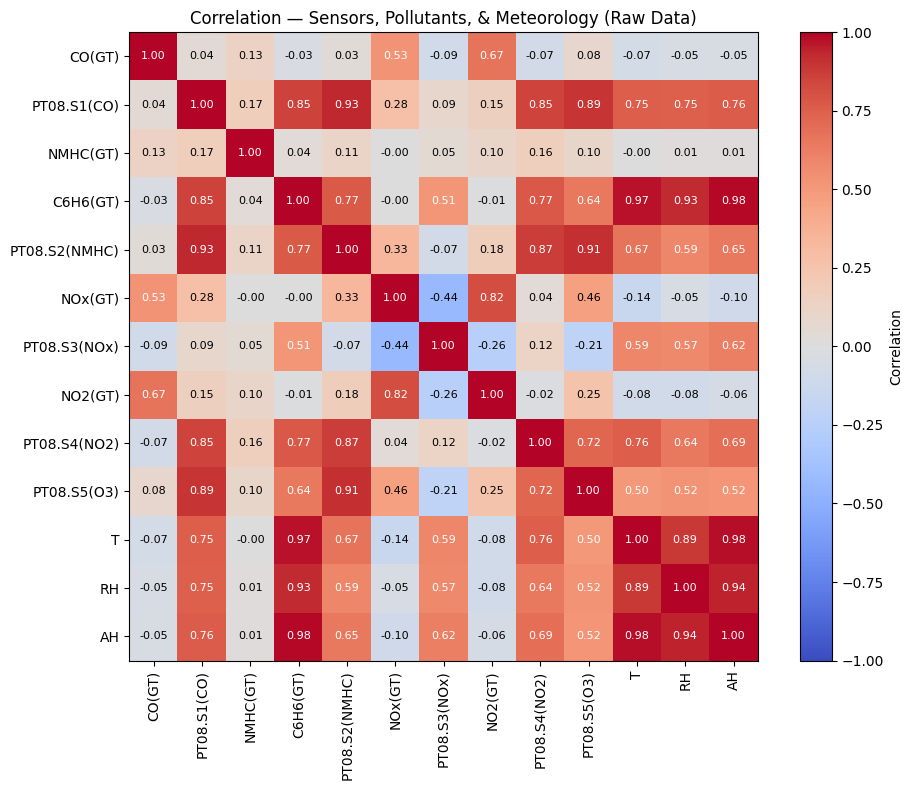

In [9]:
# ----------- 7B) Correlation: GT + PT08 sensors + meteorology (annotated, safe selection) ----------
# Safe column selection to avoid including the string 'Time'
candidates = []
for c in df_raw.columns:
    if "(GT)" in c or c.startswith("PT08.") or c in {"T", "RH", "AH"}:
        candidates.append(c)

# Coerce to numeric and keep columns that have at least some numeric data
df_num = pd.DataFrame({c: pd.to_numeric(df_raw[c], errors="coerce") for c in candidates})
keep_cols = [c for c in df_num.columns if df_num[c].notna().any()]

corr_full = df_num[keep_cols].corr()

plt.figure(figsize=(10, 8))
im = plt.imshow(corr_full, cmap="coolwarm", vmin=-1, vmax=1)

# Numeric annotations
for i in range(len(keep_cols)):
    for j in range(len(keep_cols)):
        val = corr_full.iloc[i, j]
        plt.text(j, i, f"{val:.2f}",
                 ha="center", va="center",
                 color=("black" if abs(val) < 0.5 else "white"),
                 fontsize=8)

plt.xticks(np.arange(len(keep_cols)), keep_cols, rotation=90)
plt.yticks(np.arange(len(keep_cols)), keep_cols)
plt.title("Correlation — Sensors, Pollutants, & Meteorology (Raw Data)")
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()
